# 21 · Encoding cost

**Question.** What does one query of the walk cost in each form: its looseness α_R/‖R‖, its ancilla and its gates, and how do they grow with n?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p3_pillar1", "p5_encode", "p2_reproduction", "p5_build")
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p3_pillar1: 104 records, 104 ok
p5_encode: 60 records, 60 ok
p2_reproduction: 327 records, 327 ok
p5_build: 224 records, 224 ok


In [2]:
from IPython.display import Markdown, display

from pihm.pipeline.results import reference_builds
from pihm.pipeline.summary import encoding_comparison

FORMS, COSTS = ("standard", "descriptor"), ("looseness", "ancilla", "cx")
comparison = encoding_comparison(
    (results.rows("p3_pillar1"), reference_builds(results.rows("p2_reproduction")).values()),
    (results.rows("p5_encode"), reference_builds(results.rows("p5_build")).values()),
)
top = {}
for row in comparison:
    if row["n"] >= top.get(row["problem"], {"n": -1})["n"]:
        top[row["problem"]] = row
largest = [
    {"problem": p, "n": r["n"], "form": form, **{c: r[f"{c}_{form}"] for c in COSTS}}
    for p, r in top.items()
    for form in FORMS
]


def span(values, fmt):
    """Return a range of values, formatted, or the one value they all share."""
    low, high = f"{min(values):{fmt}}", f"{max(values):{fmt}}"
    return low if low == high else f"{low} to {high}"


def growth(form):
    """Return the range, over problems, of the ancilla added per qubit from the least n."""
    per_qubit = []
    for problem, last in top.items():
        first = min((r for r in comparison if r["problem"] == problem), key=lambda r: r["n"])
        if last["n"] > first["n"]:
            added = last[f"ancilla_{form}"] - first[f"ancilla_{form}"]
            per_qubit.append(added / (last["n"] - first["n"]))
    return span(per_qubit, ".2g")


sizes = span([r["n"] for r in top.values()], "d")
lines = [f"At each problem's largest n both forms encoded, n = {sizes}:"]
for form in FORMS:
    rows = [r for r in largest if r["form"] == form]
    loose = span([r["looseness"] for r in rows if r["looseness"] == r["looseness"]], ".3g")
    ancilla, cx = span([r["ancilla"] for r in rows], "d"), span([r["cx"] for r in rows], ",d")
    lines.append(
        f"- The {form} form: α_R/‖R‖ is {loose}, the ancilla {ancilla} (adding {growth(form)} "
        f"per qubit), and a query of V {cx} cx."
    )
ratios = [r["cx_descriptor"] / r["cx_standard"] for r in top.values()]
lines.append(
    f"- The descriptor's query costs {span(ratios, '.2g')} times the standard form's cx, fewer "
    f"on {sum(x < 1.0 for x in ratios)} of {len(ratios)} problems."
)
display(Markdown("\n".join(lines)))

At each problem's largest n both forms encoded, n = 5:
- The standard form: α_R/‖R‖ is 2.06 to 2.3e+03, the ancilla 10 to 18 (adding 1 per qubit), and a query of V 2,668 to 76,250 cx.
- The descriptor form: α_R/‖R‖ is 1.12 to 4.09, the ancilla 7 to 22 (adding 0.33 to 0.67 per qubit), and a query of V 6,722 to 175,832 cx.
- The descriptor's query costs 0.65 to 2.9 times the standard form's cx, fewer on 5 of 15 problems.

Each problem at its largest n both forms encoded: the looseness, by which a query exceeds an
ideal encoding's, the ancilla, and the transpiled cx of one query of V.

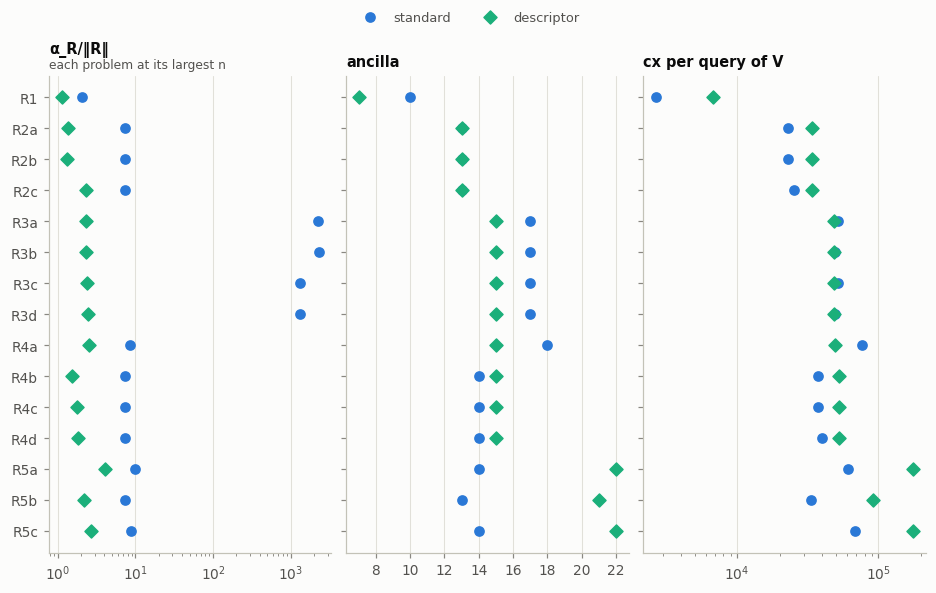

In [3]:
plotting.panel_dots(
    largest,
    [("looseness", "α_R/‖R‖"), ("ancilla", "ancilla"), ("cx", "cx per query of V")],
    title="each problem at its largest n",
    linear=["ancilla"],
);

The same three costs against n, for a regular one-axis panel, a singular one and a two-axis one.

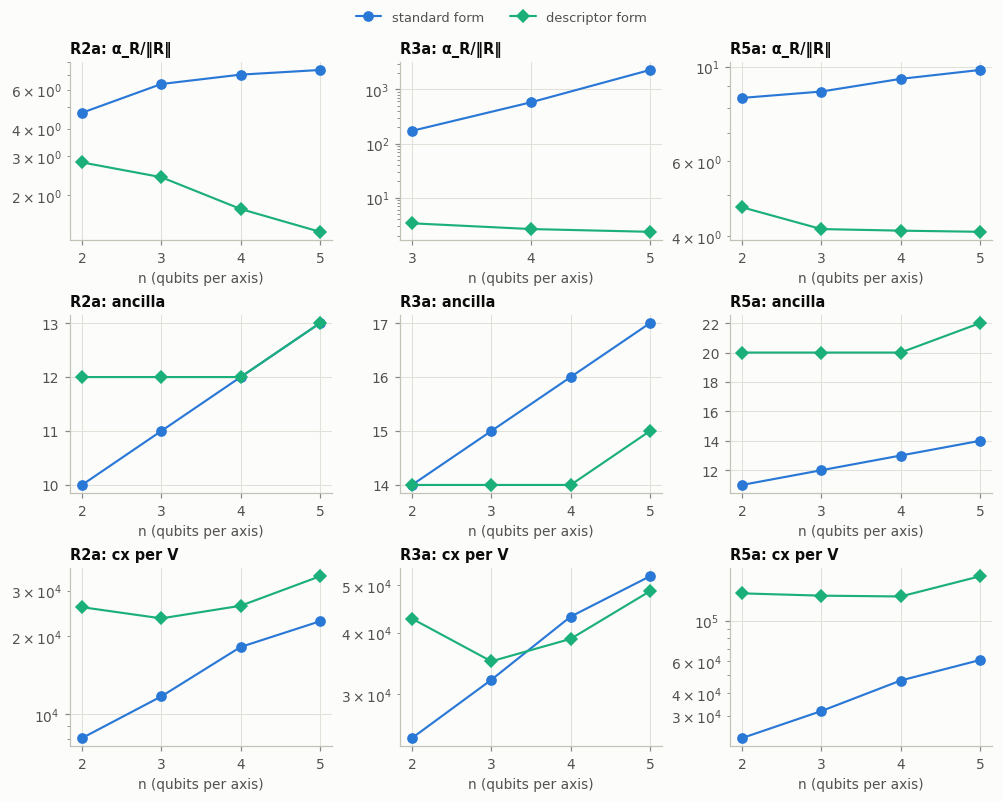

In [4]:
plotting.both_forms(
    comparison,
    ["R2a", "R3a", "R5a"],
    metrics=(("looseness", "α_R/‖R‖"), ("ancilla", "ancilla"), ("cx", "cx per V")),
    columns=3,
    linear=["ancilla"],
);

**What this does not show.** These are the cost of one query; the queries a preparation needs
are notebook 40's and 41's. The looseness is blank where a case has no build. The standard form's
records include the paper's panels as printed, which the descriptor does not run.